# Freight rate prediction: exploratory data analysis

This notebook records what the data showed and why the pipeline in `src/` is built the way it is.
Run it after `python -m src.train`, `python -m src.diagnostics` and `python -m src.predict` + `score.py`
(it reads the backtest results, the trained model's price level and the December chart).
Every chart is also saved to `reports/figures/` for the written report.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src import config, data, features

pd.set_option("display.width", 140)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10, "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 160,
})


def save(fig, name):
    fig.savefig(config.FIGURES_DIR / f"{name}.png", bbox_inches="tight")

## 1. The data at a glance

In [2]:
train_raw, validation_raw, december_raw = data.load_train_test(), data.load_validation(), data.load_december_inputs()
for name, frame in [("train_test", train_raw), ("validation", validation_raw), ("december_chart_inputs", december_raw)]:
    print(f"{name:22s} {len(frame):>6,} rows  {frame['date'].min():%Y-%m-%d} -> {frame['date'].max():%Y-%m-%d}")
    print(f"{'':22s} columns: {list(frame.columns)}")
train_raw.head()

train_test             48,000 rows  2025-01-01 -> 2025-10-31
                       columns: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']
validation             12,000 rows  2025-11-01 -> 2025-12-31
                       columns: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']
december_chart_inputs      31 rows  2025-12-01 -> 2025-12-31
                       columns: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [3]:
train_cities = set(train_raw["pickup"]) | set(train_raw["delivery"])
validation_cities = set(validation_raw["pickup"]) | set(validation_raw["delivery"])
unseen = sorted(validation_cities - train_cities)
rate_per_mile = train_raw[config.TARGET] / train_raw["distance"]
touches_unseen = ~validation_raw["pickup"].isin(train_cities) | ~validation_raw["delivery"].isin(train_cities)
quality = pd.DataFrame(
    [
        ("Negative weight", (train_raw["weight"] < 0).sum(), (validation_raw["weight"] < 0).sum()),
        ("Missing weight", train_raw["weight"].isna().sum(), validation_raw["weight"].isna().sum()),
        ("Weight at the 47,500 lb cap", (train_raw["weight"].abs() == config.WEIGHT_CAP).sum(), (validation_raw["weight"].abs() == config.WEIGHT_CAP).sum()),
        ("Missing market_index", train_raw["market_index"].isna().sum(), validation_raw["market_index"].isna().sum()),
        ("Rate above $10/mile", (rate_per_mile > 10).sum(), None),
        ("Rate below $0.50/mile", (rate_per_mile < 0.5).sum(), None),
        ("Loads touching a city unseen in training", None, touches_unseen.sum()),
    ],
    columns=["issue", "train_test", "validation"],
)
print("Cities in validation but not in training:", unseen)
quality

Cities in validation but not in training: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']


,issue,train_test,validation
0,Negative weight,292.0,145.0
1,Missing weight,300.0,165.0
2,"Weight at the 47,500 lb cap",1204.0,301.0
3,Missing market_index,374.0,249.0
4,Rate above $10/mile,49.0,NaN
5,Rate below $0.50/mile,103.0,NaN
6,Loads touching a city unseen in training,NaN,1447.0


## 2. Broken prices

Each load's log rate is compared with a robust log-linear estimate (lane, equipment, distance, weight, market_index, month).
Normal loads sit within about ±15% of the estimate; a separate group sits 2-7x away with **nothing in between**.
Those are data-entry errors: they are excluded from training and reported separately in every backtest.

Flagged 677 of 48,000 loads (1.4%): 340 too high, 337 too low
Clean-load residual std: 0.024 log units (~2.4%)


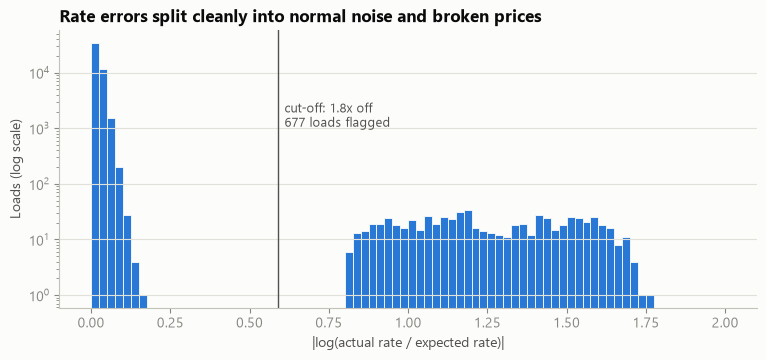

In [4]:
tables = data.build_reference_tables(train_raw, validation_raw)
train = data.clean_features(train_raw, tables)
residual = data.price_residuals(train)
outlier = residual.abs() > config.OUTLIER_LOG_THRESHOLD
too_high = (residual > config.OUTLIER_LOG_THRESHOLD).sum()
too_low = (residual < -config.OUTLIER_LOG_THRESHOLD).sum()
print(f"Flagged {outlier.sum():,} of {len(train):,} loads ({outlier.mean():.1%}): {too_high} too high, {too_low} too low")
print(f"Clean-load residual std: {residual[~outlier].std():.3f} log units (~{np.expm1(residual[~outlier].std()):.1%})")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(residual.abs(), bins=np.linspace(0, 2.0, 81), color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax.set_yscale("log")
ax.axvline(config.OUTLIER_LOG_THRESHOLD, color=INK_2, linewidth=1)
ax.text(config.OUTLIER_LOG_THRESHOLD + 0.02, 3000, f"cut-off: 1.8x off\n{outlier.sum():,} loads flagged", color=INK_2, fontsize=9, va="top")
ax.set_title("Rate errors split cleanly into normal noise and broken prices")
ax.set_xlabel("|log(actual rate / expected rate)|")
ax.set_ylabel("Loads (log scale)")
save(fig, "outlier_residuals")

## 3. What drives price

Shorter trips cost more per mile, Reefer > Flatbed > Dry Van, and the relationship is close to multiplicative,
which is why the models work on log(rate).

equipment,Dry Van,Flatbed,Reefer
distance,,,
"(0, 150]",2.76,3.00,3.11
"(150, 300]",2.52,2.74,2.85
"(300, 500]",2.30,2.50,2.60
"(500, 800]",2.14,2.32,2.42
"(800, 1200]",2.04,2.20,2.31
"(1200, 2000]",1.95,2.11,2.20
"(2000, 3500]",1.84,1.99,2.08


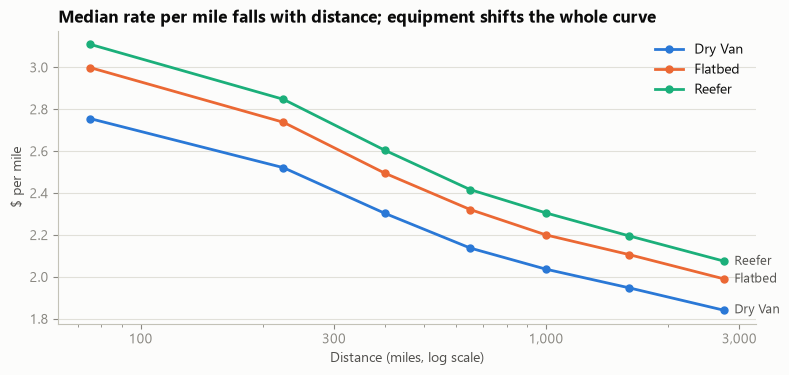

In [5]:
clean = train[~outlier].assign(rate_per_mile=lambda f: f[config.TARGET] / f["distance"])
bands = pd.cut(clean["distance"], [0, 150, 300, 500, 800, 1200, 2000, 3500])
by_band = clean.groupby([bands, "equipment"], observed=True)["rate_per_mile"].median().unstack()
midpoints = [interval.mid for interval in by_band.index]

fig, ax = plt.subplots(figsize=(9, 3.8))
for equipment, color in zip(config.EQUIPMENT_TYPES, [BLUE, ORANGE, AQUA]):
    ax.plot(midpoints, by_band[equipment], color=color, marker="o", markersize=5, label=equipment)
    ax.text(midpoints[-1] * 1.06, by_band[equipment].iloc[-1], equipment, color=INK_2, va="center", fontsize=9)
ax.set_xscale("log")
ax.set_xticks([100, 300, 1000, 3000], ["100", "300", "1,000", "3,000"])
ax.set_title("Median rate per mile falls with distance; equipment shifts the whole curve")
ax.set_xlabel("Distance (miles, log scale)")
ax.set_ylabel("$ per mile")
ax.legend(loc="upper right")
save(fig, "rate_per_mile_by_distance")
by_band.round(2)

## 4. The `quote_signal` trap

`quote_signal` changes behaviour from week to week:
- in some weeks it **equals** price per mile (a leak of the answer),
- in others it is a **mirror** of it (strongly negative),
- and in late July to August it is **pure noise**.

Validation has no labels, but in every labelled month `quote_signal` is strongly correlated with distance (because price per mile is),
so that correlation reveals the state without the answer. In **November and December it is ~0, like August: noise**.
A model using it would apply a relationship that no longer holds, so the feature is dropped.

,corr_quote_signal_distance
date,
2025-01,-0.721
2025-02,-0.715
2025-03,-0.697
2025-04,0.713
2025-05,0.725
2025-06,-0.700
2025-07,0.716
2025-08,0.015
2025-09,-0.701


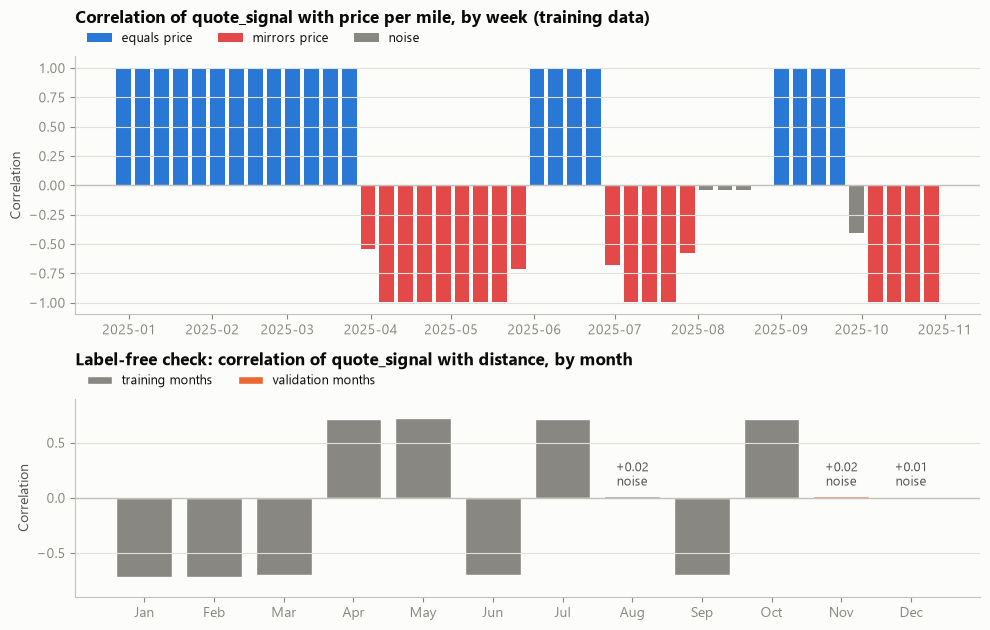

In [6]:
week_start = clean["date"].dt.to_period("W-SUN").dt.start_time
weekly = clean.groupby(week_start).apply(lambda f: f["quote_signal"].corr(f["rate_per_mile"]))
state = np.select([weekly > 0.5, weekly < -0.5], ["equals price", "mirrors price"], "noise")

inputs = pd.concat([train_raw.assign(source="train"), validation_raw.assign(source="validation")])
monthly = inputs.groupby(inputs["date"].dt.to_period("M")).apply(lambda f: f["quote_signal"].corr(f["distance"]))
is_validation = monthly.index.month >= 11
month_labels = monthly.index.strftime("%b")

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6.4), gridspec_kw={"height_ratios": [1.3, 1]})
for label, color in {"equals price": BLUE, "mirrors price": RED, "noise": MUTED}.items():
    mask = state == label
    top.bar(weekly.index[mask], weekly[mask], width=5.5, color=color, label=label)
top.axhline(0, color=AXIS, linewidth=1)
top.set_title("Correlation of quote_signal with price per mile, by week (training data)", pad=24)
top.set_ylabel("Correlation")
top.set_ylim(-1.1, 1.1)
top.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)

bottom.bar(month_labels[~is_validation], monthly[~is_validation], color=MUTED, edgecolor=SURFACE, label="training months")
bottom.bar(month_labels[is_validation], monthly[is_validation], color=ORANGE, edgecolor=SURFACE, label="validation months")
bottom.axhline(0, color=AXIS, linewidth=1)
for position, value in enumerate(monthly):
    if abs(value) < 0.1:
        bottom.text(position, 0.08, f"{value:+.2f}\nnoise", ha="center", va="bottom", fontsize=9, color=INK_2)
bottom.set_title("Label-free check: correlation of quote_signal with distance, by month", pad=24)
bottom.set_ylabel("Correlation")
bottom.set_ylim(-0.9, 0.9)
bottom.legend(ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)
fig.tight_layout()
save(fig, "quote_signal_regimes")
pd.DataFrame({"corr_quote_signal_distance": monthly.round(3)})

## 5. Market index and the price level over time

`market_index` is a daily number (about 98% of its variance is explained by the date) with a weekly cycle,
so missing values are filled with that day's median and the December chart can use each day's value from `validation.csv`.

On top of it, all prices on a day move together in a way the inputs don't explain. The model measures this daily price
level (on out-of-fold predictions) and finds two patterns: a **slow upward trend** and a **~4% climb over the last four
weeks of each quarter that resets when the next quarter starts**. For Nov-Dec it carries the recent level forward,
continues the trend and adds the ramp into the December quarter end.

Trend +0.59% per month; quarter-end ramp +4.06%; recent level +2.76% vs. the Jan-Oct average


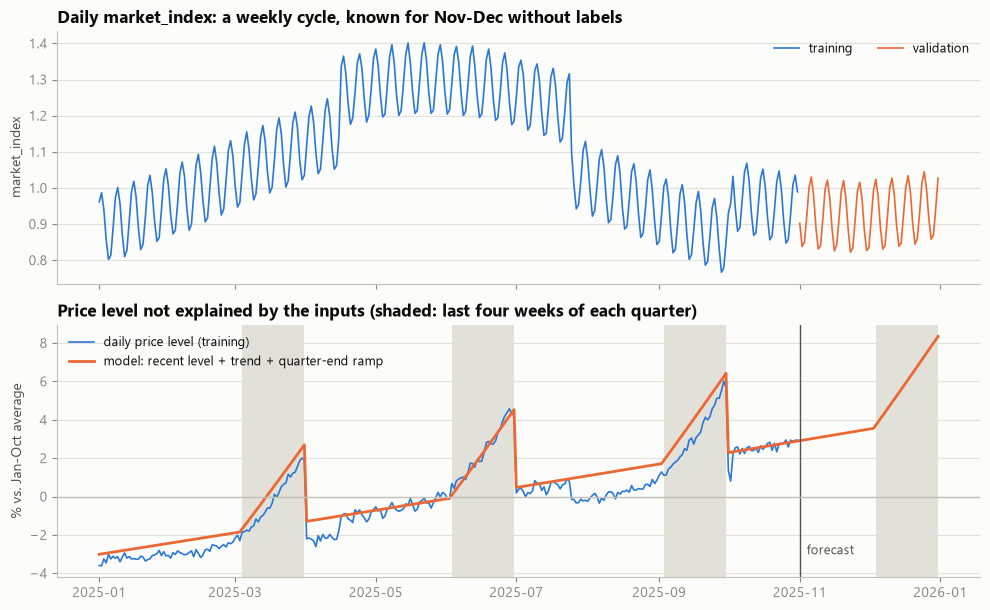

In [7]:
model = joblib.load(config.MODEL_PATH)["model"]
baseline = model.daily_level_.mean()
daily_level = np.expm1(model.daily_level_ - baseline) * 100
all_days = pd.Series(pd.date_range("2025-01-01", "2025-12-31", freq="D"))
level_inputs = pd.DataFrame({"date": all_days, "quarter_end_proximity": features.quarter_end_proximity(all_days)})
modelled_level = pd.Series(np.expm1(model.market_level(level_inputs) - baseline) * 100, index=all_days)
daily_market = inputs.groupby(["date", "source"])["market_index"].mean().unstack()

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True)
top.plot(daily_market.index, daily_market["train"], color=BLUE, linewidth=1.2, label="training")
top.plot(daily_market.index, daily_market["validation"], color=ORANGE, linewidth=1.2, label="validation")
top.set_title("Daily market_index: a weekly cycle, known for Nov-Dec without labels")
top.set_ylabel("market_index")
top.legend(loc="upper right", ncol=2, fontsize=9)

for quarter_end in pd.to_datetime(["2025-03-31", "2025-06-30", "2025-09-30", "2025-12-31"]):
    bottom.axvspan(quarter_end - pd.Timedelta(days=27), quarter_end, color=GRID, linewidth=0)
bottom.plot(daily_level.index, daily_level, color=BLUE, linewidth=1.2, label="daily price level (training)")
bottom.plot(modelled_level.index, modelled_level, color=ORANGE, linewidth=2, label="model: recent level + trend + quarter-end ramp")
bottom.axvline(pd.Timestamp("2025-11-01"), color=INK_2, linewidth=1)
bottom.text(pd.Timestamp("2025-11-04"), modelled_level.min(), "forecast", color=INK_2, fontsize=9)
bottom.axhline(0, color=AXIS, linewidth=1)
bottom.set_title("Price level not explained by the inputs (shaded: last four weeks of each quarter)")
bottom.set_ylabel("% vs. Jan-Oct average")
bottom.legend(loc="upper left", fontsize=9)
fig.tight_layout()
save(fig, "market_index_and_level")
print(f"Trend {np.expm1(model.trend_per_day_ * 30):+.2%} per month; quarter-end ramp {np.expm1(model.ramp_effect_):+.2%}; "
      f"recent level {np.expm1(model.level_ - baseline):+.2%} vs. the Jan-Oct average")

## 6. New cities in validation

Eight validation cities never appear in training. The tree model uses coordinates rather than city names, so it can price them.
A test that hid 8 training cities (results in section 7) shows the coordinate-based model handles them far better than a city-name model.

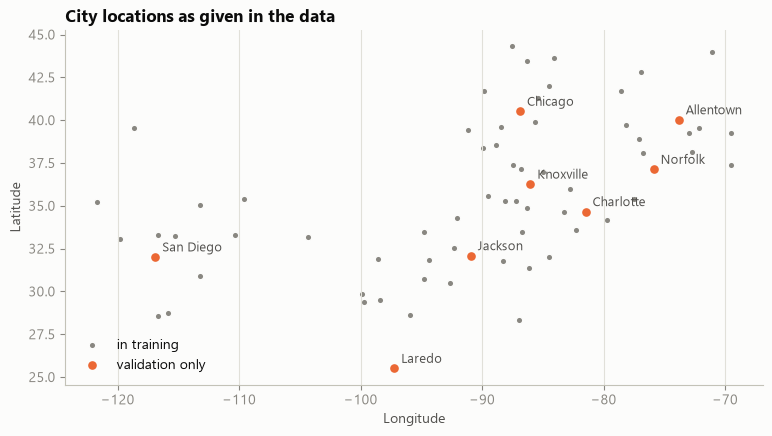

In [8]:
coords = tables.city_coords
seen = coords[coords.index.isin(train_cities)]
new = coords[~coords.index.isin(train_cities)]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.scatter(seen["lon"], seen["lat"], s=22, color=MUTED, edgecolor=SURFACE, linewidth=1, label="in training")
ax.scatter(new["lon"], new["lat"], s=60, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, label="validation only")
for city, row in new.iterrows():
    ax.annotate(city, (row["lon"], row["lat"]), xytext=(5, 4), textcoords="offset points", fontsize=9, color=INK_2)
ax.set_title("City locations as given in the data")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(axis="both")
ax.legend(loc="lower left")
save(fig, "cities")

## 7. Backtest results

Three rolling folds each train on the past and predict the next two months, mirroring Jan-Oct -> Nov-Dec.
Models are compared on mean and worst-fold MAE over clean test loads.

,MAE,worst,RMSE,MAPE,raw_MAE
model,,,,,
Blend + market level,44.47,51.42,64.59,1.89,98.41
LightGBM + market level,45.84,54.69,66.26,1.96,99.76
LightGBM + recent level,56.38,62.08,82.86,2.38,110.19
Log-linear,74.56,115.24,103.90,3.13,128.14
LightGBM,77.45,117.61,106.35,3.24,130.98
Naive $/mile,105.74,147.95,143.43,4.59,158.99


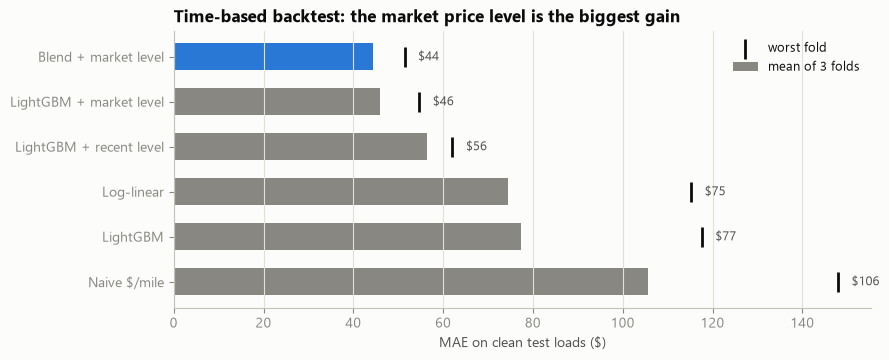

In [9]:
results = pd.read_csv(config.BACKTEST_RESULTS_PATH)
summary = (
    results.groupby("model")
    .agg(MAE=("MAE", "mean"), worst=("MAE", "max"), RMSE=("RMSE", "mean"), MAPE=("MAPE", "mean"), raw_MAE=("raw_MAE", "mean"))
    .sort_values("MAE", ascending=False)
)
selected = json.loads(config.METADATA_PATH.read_text())["selected_model"]

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(summary))
ax.barh(y, summary["MAE"], height=0.6, color=[BLUE if name == selected else MUTED for name in summary.index], label="mean of 3 folds")
ax.scatter(summary["worst"], y, marker="|", s=200, color=INK, linewidths=2, label="worst fold", zorder=3)
for position, (name, row) in enumerate(summary.iterrows()):
    ax.text(row["worst"] + 3, position, f"${row['MAE']:.0f}", va="center", fontsize=9, color=INK_2)
ax.set_yticks(y, summary.index)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("MAE on clean test loads ($)")
ax.set_title("Time-based backtest: the market price level is the biggest gain")
ax.legend(loc="upper right", fontsize=9)
save(fig, "backtest_mae")
summary.sort_values("MAE").round(2)

In [10]:
diagnostics = json.loads((config.REPORTS_DIR / "diagnostics.json").read_text())
display(pd.DataFrame(diagnostics["split_comparison"]))
display(pd.DataFrame(diagnostics["quote_signal_by_month"]))
pd.DataFrame(diagnostics["unseen_cities"]).drop(columns="hidden_cities")

,split,features,MAE
0,Random 80/20,with quote_signal,38.5
1,Random 80/20,without quote_signal,51.6
2,Time: Jan-Aug -> Sep-Oct,with quote_signal,91.8
3,Time: Jan-Aug -> Sep-Oct,without quote_signal,117.6


,month,corr_quote_signal_rate_per_mile,corr_quote_signal_distance,MAE_with_quote_signal,MAE_without_quote_signal
0,2025-01,0.996,-0.722,83.0,117.2
1,2025-02,0.996,-0.715,44.6,69.9
2,2025-03,0.997,-0.698,39.8,51.0
3,2025-04,-0.993,0.713,47.5,56.9
4,2025-05,-0.994,0.724,33.2,45.0
5,2025-06,0.997,-0.700,71.0,71.5
6,2025-07,-0.994,0.716,34.4,36.6
7,2025-08,-0.020,0.013,80.5,36.5
8,2025-09,0.997,-0.701,91.1,110.0
9,2025-10,-0.994,0.715,68.2,82.9


,model,MAE_on_unseen_city_loads
0,Log-linear (city one-hot),70.1
1,LightGBM (coordinates),56.9
2,Blend,57.0


## 8. December chart

Only the date changes. The prediction follows the weekly `market_index` cycle (peaking mid-week), drifts up with the
trend, and climbs over the last four weeks of the quarter as prices did at the end of March, June and September.
The training data contains no December and showed no holiday effect around July 4th or Memorial Day, so no
Christmas-specific effect is assumed.

December predictions: $836 to $893


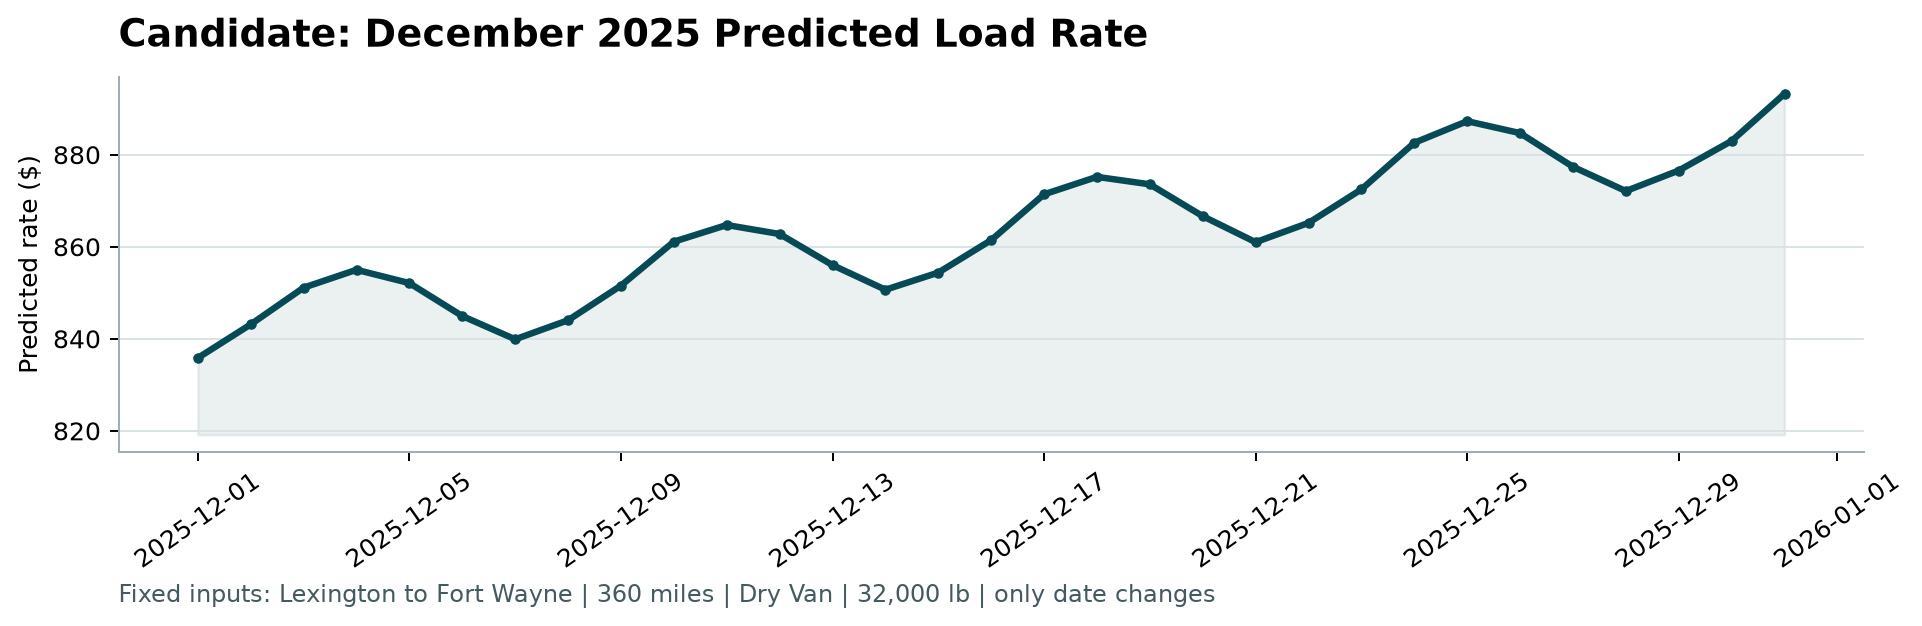

In [11]:
december = pd.read_csv(config.DECEMBER_PREDICTIONS_PATH)
print(f"December predictions: ${december['predicted_rate'].min():,.0f} to ${december['predicted_rate'].max():,.0f}")
Image(filename=str(ROOT / "scorer_results" / "candidate_december.png"))